EDA Awal: Target, Sinyal, dan Cakupan (fadhlur)

Ringkasan temuan awal yang mengarahkan strategi fitur.
Data: `data/*.csv`. Semua angka dihitung di notebook ini.

## 0. Setup

In [1]:
import matplotlib

matplotlib.use("Agg")
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display
from scipy.stats import ks_2samp


def find_repo_root(marker="data/train_applications.csv"):
    d = Path.cwd()
    for _ in range(6):
        if (d / marker).exists():
            return d / "data"
        d = d.parent
    raise FileNotFoundError("repo root dengan data/ tidak ditemukan")

DATA = str(find_repo_root())
SEED = 42
FIGDIR = str(find_repo_root().parent / "outputs" / "analysis" / "figures")
os.makedirs(FIGDIR, exist_ok=True)


def save_show(fig, name):
    path = os.path.join(FIGDIR, name)
    fig.savefig(path, dpi=110, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=path))


save_show.counter = 0

## 1. Target overall dan stabilitas waktu

Target 13,58%. Stabil per bulan (12-15%) — stratified 5-fold sah,
time-split hanya robustness check.

In [2]:
tr = pd.read_csv(f"{DATA}/train_applications.csv", parse_dates=["decision_datetime"])
print("train rows:", len(tr), "| positive rate:", round(tr.target.mean(), 4))
tr["ym"] = tr.decision_datetime.dt.to_period("M").astype(str)
print(tr.groupby("ym").target.agg(["mean", "count"]).round(4).to_string())
print(tr.groupby("loan_purpose").target.mean().round(4).to_string())

train rows: 70000 | positive rate: 0.1358
           mean  count
ym                    
2025-01  0.1430   5778
2025-02  0.1473   5898
2025-03  0.1384   5809
2025-04  0.1308   5910
2025-05  0.1201   5864
2025-06  0.1354   5776
2025-07  0.1289   5739
2025-08  0.1362   5809
2025-09  0.1266   5830
2025-10  0.1404   5854
2025-11  0.1436   5821
2025-12  0.1390   5912
loan_purpose
education           0.1365
home_improvement    0.1352
household           0.1382
medical             0.1363
working_capital     0.1330


## 1b. Visual: stabilitas target

Target rate datar per bulan maupun kategori — tidak ada drift yang
memaksa time-split.

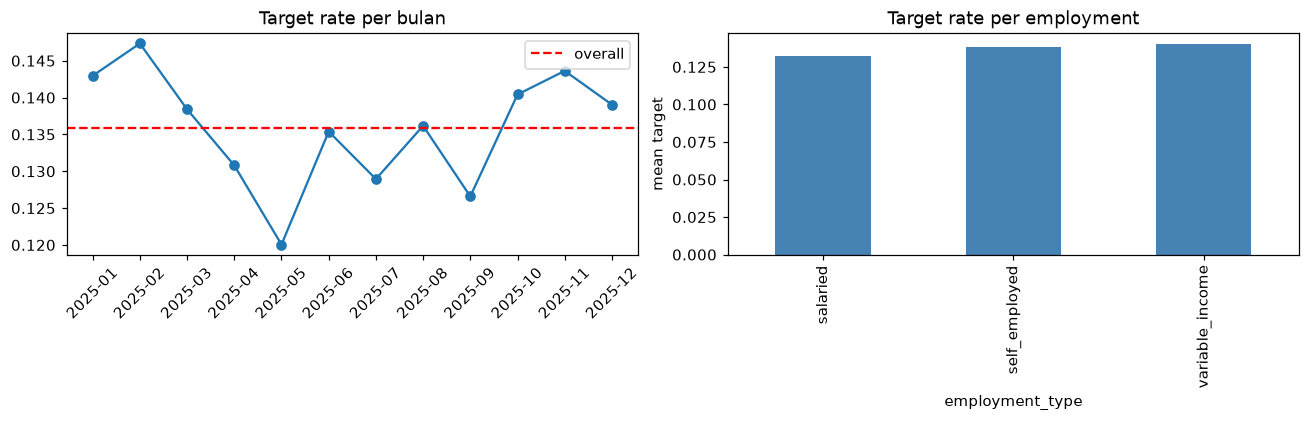

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
monthly = tr.groupby("ym").target.mean()
ax[0].plot(monthly.index, monthly.values, marker="o")
ax[0].axhline(tr.target.mean(), color="red", linestyle="--", label="overall")
ax[0].set_title("Target rate per bulan")
ax[0].tick_params(axis="x", rotation=45)
ax[0].legend()
prof = pd.read_csv(f"{DATA}/customer_profiles.csv")
t = tr.merge(prof, on="customer_id")
t.groupby("employment_type").target.mean().plot.bar(ax=ax[1], color="steelblue")
ax[1].set_title("Target rate per employment")
ax[1].set_ylabel("mean target")
plt.tight_layout()
save_show(fig, f"eda_{save_show.counter:02d}.png"); save_show.counter += 1

## 2. Sinyal tunggal terkuat: skor bureau dan DPD historis

Skor bureau monoton (50,7% → 6,2%). DPD maksimum historis monoton
(8,5% → 51,8%). Keduanya dihitung strictly sebelum cutoff.

In [4]:
cut = tr.set_index("customer_id").decision_datetime
bur = pd.read_csv(
    f"{DATA}/bureau_observations.csv",
    usecols=["application_id", "available_datetime", "score"],
    parse_dates=["available_datetime"],
)
m = bur.merge(tr[["application_id", "decision_datetime", "target"]], on="application_id")
m = m[m.available_datetime <= m.decision_datetime]
print(m.groupby(pd.cut(m.score, [0, 500, 600, 700, 850])).target.agg(["mean", "count"]).round(4).to_string())

lc = pd.read_csv(f"{DATA}/previous_applications.csv", usecols=["loan_id", "customer_id"]).dropna().drop_duplicates("loan_id")
rp = pd.read_csv(f"{DATA}/repayment_history.csv", usecols=["loan_id", "due_date", "days_past_due"], parse_dates=["due_date"]).merge(lc, on="loan_id")
rp["cut"] = rp.customer_id.map(cut)
rp = rp[rp.cut.notna() & (rp.due_date < rp.cut)]
g = rp.groupby("customer_id").days_past_due.max()
both = pd.DataFrame({"dpdmax": g, "target": tr.set_index("customer_id").target}).dropna()
print(both.groupby(pd.cut(both.dpdmax, [-1, 0, 30, 90, 9999])).target.agg(["mean", "count"]).round(4).to_string())

              mean   count
score                     
(0, 500]    0.5070     142
(500, 600]  0.2857   17621
(600, 700]  0.1434  109280
(700, 850]  0.0623   47622


              mean  count
dpdmax                   
(-1, 0]     0.0845  30499
(0, 30]     0.1586   8202
(30, 90]    0.2890   5198
(90, 9999]  0.5180   2413


## 2b. Visual: distribusi skor dan DPD per kelas

Pemisahan visual menjelaskan KS tinggi: skor bureau bergeser kiri
untuk gagal bayar, DPD maksimum bergeser kanan.

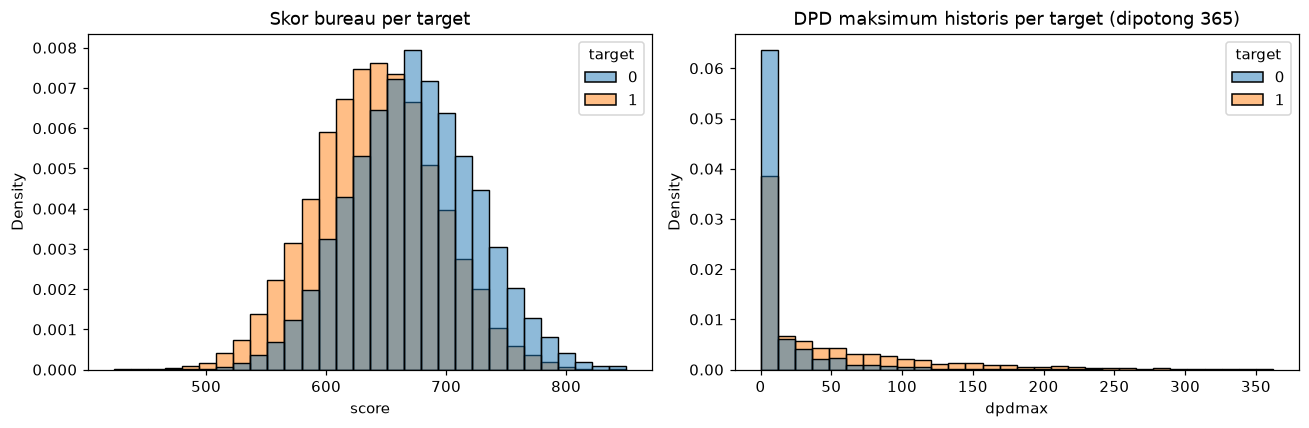

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
m_ok = m.dropna(subset=["score"])
sns.histplot(data=m_ok, x="score", hue="target", bins=30, stat="density", common_norm=False, ax=ax[0])
ax[0].set_title("Skor bureau per target")
both_ok = both[both.dpdmax < 365]
sns.histplot(data=both_ok.assign(target=both_ok.target.astype(str)), x="dpdmax", hue="target", bins=30, stat="density", common_norm=False, ax=ax[1])
ax[1].set_title("DPD maksimum historis per target (dipotong 365)")
plt.tight_layout()
save_show(fig, f"eda_{save_show.counter:02d}.png"); save_show.counter += 1

## 3. Ranking KS univariat fitur engineered

Dibangun oleh `scripts/build_features.py` (87 fitur exp018).
Teratas: `repay_pay_ratio` 0,322, `repay_dpd_max` 0,315,
`bureau_score_mean` 0,253, `annual_interest_rate` 0,230.

In [6]:
f = pd.read_parquet(f"{DATA}/train_features.parquet")
y = f.target.to_numpy()
rows = []
for c in f.columns:
    if c in ("application_id", "customer_id", "target"):
        continue
    v = f[c]
    try:
        v = v.astype(float).to_numpy()
    except (ValueError, TypeError):
        v = pd.factorize(v.astype(str))[0].astype(float)
    msk = ~np.isnan(v)
    if msk.sum() < 100 or len(np.unique(v[msk])) < 2:
        continue
    ks = ks_2samp(v[(y == 1) & msk], v[(y == 0) & msk]).statistic
    rows.append((c, round(float(ks), 4)))
for r in sorted(rows, key=lambda r: -r[1])[:15]:
    print(r)

('repay_maxdpd_mean', 0.4265)
('repay_maxdpd_max', 0.3709)
('ec3_prc_idx_mean', 0.3582)
('repay_recent_dpd_max', 0.3421)
('repay_late_ratio', 0.3282)
('repay_mean_loan_pay_ratio', 0.324)
('repay_pay_ratio', 0.322)
('repay_worst_loan_pay_ratio', 0.3189)
('repay_overdue_amt_ratio', 0.3184)
('repay_overdue_amt_sum', 0.3155)
('repay_dpd_max', 0.3151)
('repay_rec_wlate', 0.3151)
('repay_rec_wdpd', 0.3151)
('repay_worst_loan_dpd', 0.3151)
('repay_last3_dpd_mean', 0.311)


## 3b. Visual: ranking KS dan cakupan fitur

Sedikit fitur dominan (ekor panjang) — alasan seleksi fitur dan
mengapa blend model sekeluarga cepat jenuh.

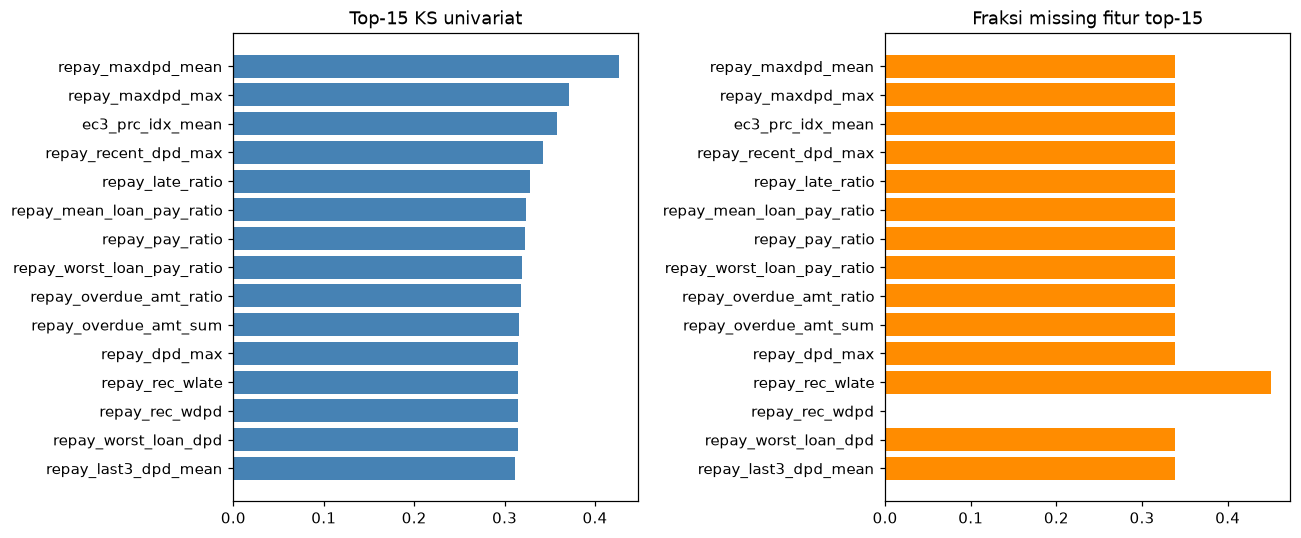

In [7]:
top = sorted(rows, key=lambda r: -r[1])[:15]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
names, vals = [r[0] for r in top][::-1], [r[1] for r in top][::-1]
ax[0].barh(names, vals, color="steelblue")
ax[0].set_title("Top-15 KS univariat")
cov = []
for c, _ in top:
    v = f[c]
    try:
        vv = v.astype(float).to_numpy()
        cov.append(float(np.isnan(vv).mean()))
    except (ValueError, TypeError):
        cov.append(0.0)
ax[1].barh(names, cov, color="darkorange")
ax[1].set_title("Fraksi missing fitur top-15")
plt.tight_layout()
save_show(fig, f"eda_{save_show.counter:02d}.png"); save_show.counter += 1

## 4. Cakupan histori dan audit leakage

Riwayat repayment hanya ada di 46k/70k train — segmen tanpa histori
butuh penanganan khusus. Audit: 0 baris bureau melewati cutoff
(filter `available_datetime <= decision_datetime` bekerja).

In [8]:
print("apps with repay history:", int((f["repay_n"] > 0).sum()), "/", len(f))
bur2 = pd.read_csv(f"{DATA}/bureau_observations.csv", usecols=["application_id", "available_datetime"], parse_dates=["available_datetime"])
cutapp = dict(zip(tr.application_id, tr.decision_datetime))
linked = bur2[bur2.application_id.isin(cutapp)]
future = (linked.available_datetime > linked.application_id.map(cutapp)).sum()
print("bureau rows linked:", len(linked), "| future rows:", int(future))
print("DONE - temuan diringkas di docs/STRATEGI_AWAL.md")

apps with repay history: 46312 / 70000


bureau rows linked: 184778 | future rows: 0
DONE - temuan diringkas di docs/STRATEGI_AWAL.md
